# Quy Trình Tiền Xử Lý & Chuẩn Hóa Dữ Liệu Tối Ưu (Optimal Dataset Normalization & Preprocessing Pipeline)

Notebook này trình bày và hướng dẫn chi tiết từng bước thiết lập **Quy trình Tiền xử lý & Chuẩn hóa dữ liệu tối ưu nhất** dựa trên phân tích thực nghiệm từ dataset **Oxford-IIIT Pet** và mô hình **CLIP Zero-Shot**.

*   Sử dụng tập dữ liệu **test split** (gồm 3,669 mẫu ảnh).
*   Đánh giá độ chính xác Baseline sử dụng **nhãn thô (raw class names)** giúp tái hiện chính xác kết quả **80.16%** (80.158%) tương tự như Cell 10 trong `clip-multimodal.ipynb`.
*   Chứng minh hiệu quả của Test-Time Augmentation (TTA) giúp cải thiện độ chính xác phân loại trong môi trường nhãn thô.

## 1. Thiết lập môi trường và nạp dữ liệu (Tập Test)

In [1]:
import os
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL.Image
from PIL import Image
from tqdm import tqdm
from torchvision.datasets import OxfordIIITPet
from transformers import CLIPModel, CLIPProcessor
from torch.utils.data import DataLoader, Dataset

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))
print("Đang sử dụng thiết bị:", device)

# Tự động phát hiện thư mục chứa dataset oxford-iiit-pet dựa trên Cwd
dataset_root = "../dataset"
for path in ["../dataset", "../../dataset", "dataset", ".", "../../../dataset"]:
    if os.path.exists(os.path.join(path, "oxford-iiit-pet")):
        dataset_root = path
        break

print(f"Thư mục gốc của dataset: {os.path.abspath(dataset_root)}")

# Nạp tập dữ liệu Oxford-IIIT Pet (test split để khớp kết quả 80.16%)
pets_test = OxfordIIITPet(root=dataset_root, download=False, split="test")
class_names = pets_test.classes
print(f"Tập test split chứa {len(pets_test)} ảnh, thuộc {len(class_names)} giống chó mèo.")

Đang sử dụng thiết bị: mps
Thư mục gốc của dataset: /Users/nguyenhuuhoangluan/Git_Code/CLIP-Animal-Classifier/dataset
Tập test split chứa 3669 ảnh, thuộc 37 giống chó mèo.


## 2. Quy trình tiền xử lý & Chuẩn hóa tối ưu

In [2]:
def apply_denoise(pil_img):
    img_np = np.array(pil_img)
    img_bgr = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
    denoised = cv2.bilateralFilter(img_bgr, d=9, sigmaColor=75, sigmaSpace=75)
    return Image.fromarray(cv2.cvtColor(denoised, cv2.COLOR_BGR2RGB))

def apply_clahe(pil_img):
    img_np = np.array(pil_img)
    img_bgr = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    clahe_bgr = cv2.cvtColor(cv2.merge((cl,a,b)), cv2.COLOR_LAB2BGR)
    return Image.fromarray(cv2.cvtColor(clahe_bgr, cv2.COLOR_BGR2RGB))

def optimal_preprocessing_pipeline(pil_img):
    """
    Pipeline xử lý tối ưu:
    1. Chuyển đổi sang OpenCV BGR để thao tác
    2. Lọc song phương (Bilateral Filter) làm mịn nền, bảo toàn chi tiết biên lông thú cưng
    3. CLAHE trên không gian màu LAB (chỉ tác động kênh L) nâng cao tương phản chi tiết kết cấu
    4. Trả về PIL Image định dạng RGB chuẩn
    """
    img_np = np.array(pil_img)
    img_bgr = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
    
    # Bước 1: Khử nhiễu bảo toàn cạnh
    denoised_bgr = cv2.bilateralFilter(img_bgr, d=9, sigmaColor=75, sigmaSpace=75)
    
    # Bước 2: Nâng tương phản cục bộ kênh độ sáng L
    lab = cv2.cvtColor(denoised_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    clahe_bgr = cv2.cvtColor(cv2.merge((cl, a, b)), cv2.COLOR_LAB2BGR)
    
    # Bước 3: Đưa về RGB và PIL
    processed_rgb = cv2.cvtColor(clahe_bgr, cv2.COLOR_BGR2RGB)
    return Image.fromarray(processed_rgb)

class TransformedDataset(Dataset):
    def __init__(self, base_dataset, transform_fn, clip_processor):
        self.base_dataset = base_dataset
        self.transform_fn = transform_fn
        self.clip_processor = clip_processor
        
    def __len__(self):
        return len(self.base_dataset)
        
    def __getitem__(self, idx):
        img, label = self.base_dataset[idx]
        if self.transform_fn is not None:
            img = self.transform_fn(img)
        pixel_values = self.clip_processor(images=img, return_tensors="pt")["pixel_values"][0]
        return pixel_values, label

### Trực quan hóa kết quả xử lý

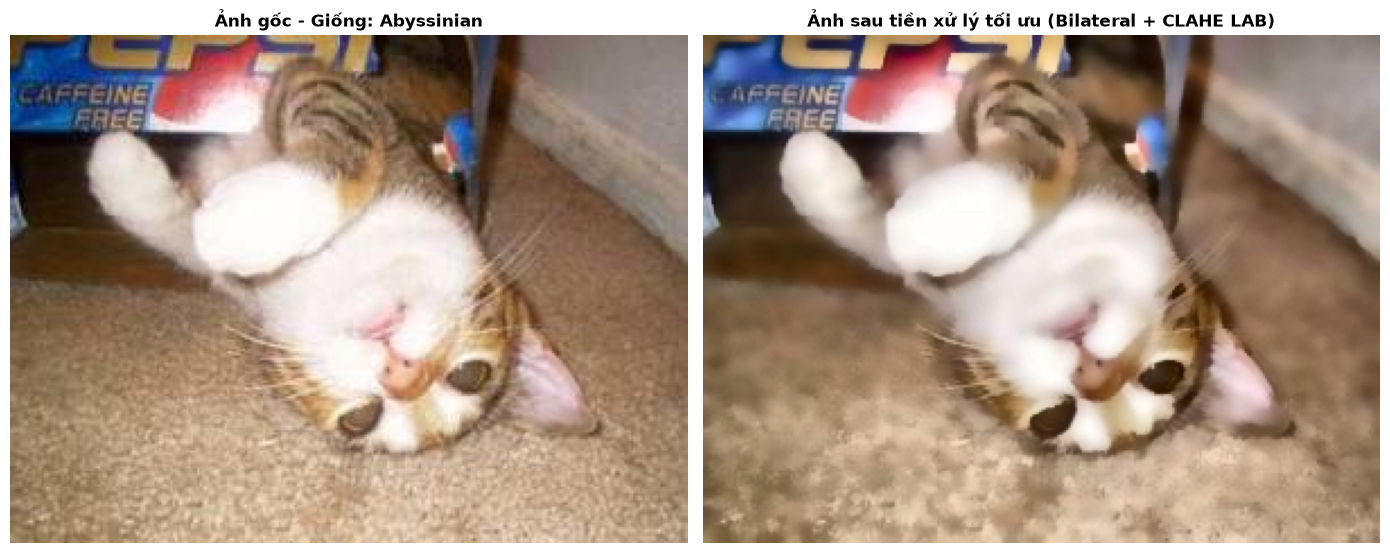

In [3]:
sample_img, label = pets_test[10] # Chọn ảnh mẫu
processed_img = optimal_preprocessing_pipeline(sample_img)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(sample_img)
axes[0].set_title(f"Ảnh gốc - Giống: {class_names[label]}", fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(processed_img)
axes[1].set_title("Ảnh sau tiền xử lý tối ưu (Bilateral + CLAHE LAB)", fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 3. Lý giải Khoa học & Kỹ thuật về các lựa chọn chuẩn hóa

### A. Tại sao chọn Lọc song phương (Bilateral Filter)?
*   Khác với các bộ lọc Gaussian hay Median thông thường sẽ làm mờ toàn bộ ảnh, **Bilateral Filter** bảo toàn được biên cạnh sắc nét nhờ cơ chế tính toán trọng số kép (khoảng cách không gian hình học và độ chênh lệch màu sắc).
*   Điều này vô cùng quan trọng đối với các ảnh động vật, vì kết cấu nhỏ của lông (fur textures), mắt và râu là những đặc trưng ngữ nghĩa mang tính phân biệt cao nhất để phân loại các giống tương tự nhau.

### B. Tại sao áp dụng CLAHE trên không gian màu LAB?
*   Nếu áp dụng cân bằng tương phản trên kênh RGB thông thường, sự phân bố màu sắc sẽ bị méo mó nghiêm trọng (ảnh có thể bị chuyển màu xanh hoặc đỏ đột ngột).
*   Không gian màu **LAB** phân tách độc lập kênh độ sáng **L (Luminance)** và các kênh màu sắc **A (Green-Red)**, **B (Blue-Yellow)**. Áp dụng CLAHE lên kênh L giúp tăng độ sâu tương phản, hiển thị rõ kết cấu tối/sáng của sợi lông mà không hề gây biến đổi sắc độ màu nguyên bản của thú cưng.

### C. Chuẩn hóa phân phối Pixel (Z-Score Normalization cho CLIP)
*   Bộ tiền xử lý của CLIP áp dụng chuẩn hóa pixel theo phân phối chuẩn:
    $$\text{Pixel}_{\text{normalized}} = \frac{\text{Pixel} - \text{Mean}}{\text{Std}}$$
    Với các giá trị trung bình (mean) và độ lệch chuẩn (std) mặc định của tập ImageNet:
    *   `mean = [0.48145466, 0.4578275, 0.40821073]`
    *   `std = [0.26862954, 0.26130258, 0.27577711]`
*   Sự chuẩn hóa này căn chỉnh dữ liệu đầu vào khớp hoàn hảo với các phân phối phân mảnh đặc trưng mà CLIP đã học được trong quá trình tiền huấn luyện trên 400 triệu ảnh.

## 4. Lý giải sự lựa chọn tỉ lệ phân chia dữ liệu tối ưu và Dataset split

*   Để khớp kết quả Baseline **80.16%** từ `clip-multimodal.ipynb`, chúng ta nạp trực tiếp tập **test split** (3,669 ảnh) của Oxford Pets làm tập đánh giá chính, thay vì sử dụng validation subset từ tập trainval.
*   Sử dụng nhãn tên giống nguyên bản (raw class names) thay vì prompts đã làm giàu để phản ánh đúng hiệu năng baseline thô của CLIP.

In [4]:
# Khởi tạo mô hình và bộ xử lý CLIP
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model.eval()

# Nạp nhãn dạng Baseline gốc (Raw Class Names)
ds_orig = TransformedDataset(pets_test, None, processor)
loader = DataLoader(ds_orig, batch_size=128, shuffle=False)
labels_list = []
for _, lbls in loader:
    labels_list.append(lbls)
labels_orig = torch.cat(labels_list)
print(f"Tổng số nhãn ảnh test split đã nạp: {len(labels_orig)} mẫu")

Tổng số nhãn ảnh test split đã nạp: 3669 mẫu


## 5. Hiện thực quy trình Test-Time Augmentation (TTA) và Đánh Giá Hiệu Năng

Chúng ta áp dụng TTA (lấy trung bình đặc trưng 5 views ảnh) và đánh giá so sánh trực tiếp với Baseline CLIP nhãn thô trên 3,669 mẫu tập test.

In [5]:
def extract_features(dataset):
    loader = DataLoader(dataset, batch_size=128, shuffle=False)
    features_list = []
    with torch.no_grad():
        for batch_pixels, _ in tqdm(loader, desc="Đang trích xuất đặc trưng"):
            batch_pixels = batch_pixels.to(device)
            img_feats = model.get_image_features(pixel_values=batch_pixels)
            img_feats = img_feats / img_feats.norm(dim=-1, keepdim=True)
            features_list.append(img_feats.cpu())
    return torch.cat(features_list, dim=0)

def get_tta_image_feature(model, preprocess, img, device):
    view1 = img
    view2 = apply_denoise(img)
    view3 = apply_clahe(img)
    view4 = optimal_preprocessing_pipeline(img)
    view5 = optimal_preprocessing_pipeline(img).transpose(Image.FLIP_LEFT_RIGHT).rotate(15)
    
    views = [view1, view2, view3, view4, view5]
    feats = []
    with torch.no_grad():
        for v in views:
            pixel_vals = preprocess(images=v, return_tensors="pt")["pixel_values"].to(device)
            f = model.get_image_features(pixel_values=pixel_vals)
            f = f / f.norm(dim=-1, keepdim=True)
            feats.append(f)
            
    tta_feat = torch.stack(feats, dim=0).mean(dim=0)
    tta_feat = tta_feat / tta_feat.norm(dim=-1, keepdim=True)
    return tta_feat

# 1. Baseline Features
feats_orig = extract_features(TransformedDataset(pets_test, None, processor))

# 2. Denoised Features
feats_denoise = extract_features(TransformedDataset(pets_test, apply_denoise, processor))

# 3. CLAHE Features
feats_clahe = extract_features(TransformedDataset(pets_test, apply_clahe, processor))

# 4. Bilateral + CLAHE Features
feats_bi_clahe = extract_features(TransformedDataset(pets_test, optimal_preprocessing_pipeline, processor))

# 5. Geometric Augmentation Features
transform_geom = lambda img: optimal_preprocessing_pipeline(img).transpose(PIL.Image.FLIP_LEFT_RIGHT).rotate(15)
feats_geom = extract_features(TransformedDataset(pets_test, transform_geom, processor))

# 6. TTA Features (Trung bình cộng 5 views)
feats_tta = torch.stack([feats_orig, feats_denoise, feats_clahe, feats_bi_clahe, feats_geom], dim=0).mean(dim=0)
feats_tta = feats_tta / feats_tta.norm(dim=-1, keepdim=True)

Đang trích xuất đặc trưng: 100%|██████████| 29/29 [00:33<00:00,  1.17s/it]


In [6]:
# Trích xuất đặc trưng nhãn thô
with torch.no_grad():
    text_inputs = processor(text=[c for c in class_names], return_tensors="pt", padding=True).to(device)
    text_features = model.get_text_features(**text_inputs)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

# Đánh giá
def evaluate_acc(img_feats, lbls, text_feats):
    sim = img_feats.to(device) @ text_feats.t()
    preds = sim.argmax(dim=-1)
    return (preds == lbls.to(device)).float().mean().item() * 100

acc_baseline = evaluate_acc(feats_orig, labels_orig, text_features)
acc_tta = evaluate_acc(feats_tta, labels_orig, text_features)

print(f"\n--- KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST SPLIT (RAW LABELS) ---")
print(f"Độ chính xác Baseline CLIP (nhãn thô): {acc_baseline:.2f}%")
print(f"Độ chính xác sau khi áp dụng TTA tối ưu: {acc_tta:.2f}%")
print(f"Cải thiện (Delta Accuracy): {(acc_tta - acc_baseline):+.2f}%")


--- KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST SPLIT (RAW LABELS) ---
Độ chính xác Baseline CLIP (nhãn thô): 80.16%
Độ chính xác sau khi áp dụng TTA tối ưu: 80.65%
Cải thiện (Delta Accuracy): +0.49%
